# Ocorrência SP · Roubo ou furto com MLP
**Global Solution · Aprendizado Profundo com Redes Neurais Convolucionais**

| Integrante | RM |
|---|---|
| Arthur Casqueira Berthi | 568017 |
| Agatha Carolina | 568352 |
| João Dyonisio | 567087 |

**Objetivo:** classificar o tipo de uma ocorrência já registrada ou hipotética da capital paulista. A saída não é uma previsão de criminalidade futura nem uma decisão jurídica.

Este notebook executa três MLPs reais e preserva as saídas. O relatório e a aplicação usam os mesmos resultados. Para executar novamente: extraia o projeto, instale `requirements.txt` e abra este arquivo pelo Jupyter na pasta `notebooks/`.

## 1. Fonte, recorte e decisões de projeto

Fonte pública efetivamente utilizada: [Crime Data in Brazil](https://www.kaggle.com/datasets/inquisitivecrow/crime-data-in-brazil), de Marco Zanchi (`inquisitivecrow`), arquivo **BO_2016.csv**, versão 1. O autor atribui a origem à SSP-SP e disponibiliza `RDO_methodology.txt` e `RDO_column_description.csv`. Os dois documentos acompanham o projeto em `docs/`. Consulta em 12/11/2026. Licença declarada no catálogo: GPL 2, registrada em `docs/source_metadata.json` e acompanhada de `LICENSE`.

A base é uma cópia histórica de dados RDO, diferente dos arquivos atuais de celulares/veículos da [SSP-SP](https://www.ssp.sp.gov.br/estatistica/consultas). O download direto do portal estava indisponível neste ambiente. O ano de 2016 é permitido pelo enunciado e permite demonstrar o fluxo completo, mas **não sustenta conclusões sobre São Paulo atual**.

**Atenção à geografia:** o dicionário descreve `CIDADE` como cidade de registro. A metodologia informa que o cidadão pode registrar um fato fora de sua circunscrição. Assim, o recorte usa `NOME_DEPARTAMENTO_CIRC = DECAP` e as oito `NOME_SECCIONAL_CIRC` da capital, que representam o local do fato. Não filtramos por delegacia de registro.

**Unidade de análise:** um BO identificado pela chave `(ID_DELEGACIA, ANO_BO, NUM_BO)`, conforme a metodologia RDO. Linhas com pessoas, objetos e naturezas podem repetir o mesmo boletim. Antes de amostrar, excluímos BOs com naturezas múltiplas, contextos/regiões conflitantes e registros sem chave válida. Consolidamos repetições e depois sorteamos 20.000 BOs, com semente 42 e proporção natural das classes.

In [1]:
from pathlib import Path
import os, sys, json, hashlib, zipfile
from sklearn.model_selection import train_test_split
ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src/data.py').exists(), 'Abra o notebook dentro do projeto extraído.'
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display, Image, Markdown
from src.data import (KEY, REGIONS, CONTEXTS, LABELS, FEATURES, SEED,
                      SOURCE, DOWNLOAD, sha256, download_raw)
print('Python:', sys.version.split()[0])
print('NumPy:', np.__version__, '| pandas:', pd.__version__, '| scikit-learn:', sklearn.__version__)
print('Semente:', SEED)

Python: 3.12.14
NumPy: 2.3.5 | pandas: 2.2.3 | scikit-learn: 1.8.0
Semente: 42


### Rótulo e entradas

| Papel | Campo da base | Transformação e motivo |
|---|---|---|
| Alvo | `RUBRICA` | Correspondência exata de Furto (art. 155) e Roubo (art. 157). Furto = 0, Roubo = 1. Excluímos outras naturezas, qualificadas e atos infracionais. |
| Entrada 1 | `NOME_SECCIONAL_CIRC` | Oito regiões administrativas da ocorrência. Localização agregada, sem endereços ou coordenadas. |
| Entrada 2 | `CONDUTA` | Dez contextos de ambiente/situação geral. Mapeamento explícito, inspecionável no código. |

**CONDUTA exige cuidado:** trata-se de um campo cadastral da ocorrência, que pode trazer classificações operacionais. O agrupamento conserva apenas ambientes/contextos e exclui “Saidinha de Banco”, cuja semântica sugere roubo. Nenhum campo com violência, ameaça, texto jurídico, `RUBRICA`, `DESDOBRAMENTO`, `FLAG_STATUS`, identificador ou dado pessoal entra na MLP. Em uma expansão do projeto, é recomendável coletar um tipo de local independente da natureza jurídica e testar a estabilidade do resultado sem `CONDUTA`.

Utilizamos apenas registros consumados (`FLAG_STATUS = C`). Campos ausentes de contexto recebem “Não informado”. Essa regra é fixa e não depende do teste. No recorte final, não há contexto ausente. Não usamos dia da semana nem horário porque o arquivo escolhido não oferece esses campos com precisão suficiente para essa decisão.

In [2]:
print('Regiões de circunscrição:', REGIONS)
display(pd.DataFrame(CONTEXTS.items(), columns=['CONDUTA original', 'contexto de entrada']))
print('Entradas permitidas:', FEATURES)
assert 'RUBRICA' not in FEATURES and 'alvo' not in FEATURES

Regiões de circunscrição: {'DEL.SEC.1º CENTRO': 'Centro', 'DEL.SEC.2º SUL': 'Sul', 'DEL.SEC.3º OESTE': 'Oeste', 'DEL.SEC.4º NORTE': 'Norte', 'DEL.SEC.5º LESTE': 'Leste', 'DEL.SEC.6º SANTO AMARO': 'Santo Amaro', 'DEL.SEC.7º ITAQUERA': 'Itaquera', 'DEL.SEC.8º SAO MATEUS': 'São Mateus'}
Entradas permitidas: ['regiao', 'contexto']


,CONDUTA original,contexto de entrada
0,TRANSEUNTE,Transeunte
1,VEICULO,Veículo
2,INTERIOR DE VEICULO,Interior de veículo
3,INTERIOR TRANSPORTE COLETIVO,Transporte coletivo
4,COLETIVO,Transporte coletivo
5,RESIDENCIA,Residência
6,CONDOMINIO RESIDENCIAL,Residência
7,ESTABELECIMENTO COMERCIAL,Comércio
8,INTERIOR ESTABELECIMENTO,Comércio
9,CONDOMINIO COMERCIAL,Comércio


## 2. Preparação implementada

O código abaixo é a mesma função de `src/data.py`. Na primeira execução, o notebook baixa a origem pública e gera a amostra de 20.000 BOs localmente. O download do ZIP tem cerca de 42 MB e o CSV descompactado cerca de 319 MB. As próximas execuções podem reutilizar a amostra local. Para forçar a preparação novamente, altere `REBUILD_FROM_SOURCE` para `True`.

Os arquivos com registros e previsões por ocorrência não acompanham a distribuição pública. O código, o modelo treinado e os resultados agregados permitem reproduzir e avaliar o experimento.

O hash SHA-256 do ZIP original e a contagem em cada filtro estão em `data/processed/auditoria.json`. O identificador exportado é um hash da chave do BO, usado somente para auditar a divisão dos conjuntos.

In [3]:
def prepare_data(raw_path=None, sample_size=20_000):
    """Filtra, elimina ambiguidades e amostra preservando proporções das classes."""
    path = Path(raw_path or ROOT / "data/raw/BO_2016.csv.zip")
    cols = KEY + ["NOME_DEPARTAMENTO_CIRC", "NOME_SECCIONAL_CIRC",
                  "FLAG_STATUS", "RUBRICA", "CONDUTA"]
    with zipfile.ZipFile(path) as z:
        frame = pd.read_csv(z.open("BO_2016.csv"), usecols=cols,
                            dtype=str, encoding="utf-8-sig")
    for col in frame:
        frame[col] = frame[col].str.strip()
    audit = {"source": SOURCE, "download": DOWNLOAD,
             "file": "BO_2016.csv", "year": 2016,
             "raw_sha256": sha256(path), "raw_rows": len(frame),
             "geography": "DECAP + oito seccionais de circunscrição da capital",
             "features": FEATURES, "seed": SEED}

    # CIDADE indica local de REGISTRO no dicionário. Não filtrar por ela.
    geo = frame.NOME_DEPARTAMENTO_CIRC.eq("DECAP") & frame.NOME_SECCIONAL_CIRC.isin(REGIONS)
    frame = frame.loc[geo].copy()
    audit["capital_rows"] = len(frame)
    # O ano do boletim integra a chave; não entra no modelo.
    valid_key = frame[KEY].notna().all(axis=1) & frame[KEY].ne("").all(axis=1)
    frame = frame.loc[valid_key].copy()
    audit["valid_key_rows"] = len(frame)

    # Primeiro examinar TODAS as naturezas do BO, antes de filtrar o alvo.
    group = frame.groupby(KEY, sort=True, dropna=False)
    natures = group.RUBRICA.nunique(dropna=False)
    single_nature_keys = natures[natures.eq(1)].index
    audit["capital_unique_bulletins"] = len(natures)
    audit["bulletins_multiple_natures_excluded"] = int(natures.gt(1).sum())
    frame = frame.set_index(KEY).loc[lambda d: d.index.isin(single_nature_keys)].reset_index()
    frame = frame.loc[frame.RUBRICA.isin(LABELS) & frame.FLAG_STATUS.eq("C")].copy()
    audit["binary_consumated_rows"] = len(frame)
    audit["label_proxy_rows_excluded"] = int(frame.CONDUTA.eq("Saidinha de Banco").sum())
    frame = frame.loc[~frame.CONDUTA.eq("Saidinha de Banco")].copy()
    frame["regiao"] = frame.NOME_SECCIONAL_CIRC.map(REGIONS)
    # Ausência de contexto será imputada com categoria explícita.
    unmapped = frame.loc[frame.CONDUTA.notna() & ~frame.CONDUTA.isin(CONTEXTS), "CONDUTA"].unique().tolist()
    if unmapped:
        raise ValueError(f"Condutas não revisadas: {unmapped}")
    frame["contexto"] = frame.CONDUTA.map(CONTEXTS).fillna("Não informado")
    frame["alvo"] = frame.RUBRICA.map(LABELS).astype(int)

    # Um BO pode ter várias pessoas/objetos. Conflito de contexto ou região:
    # excluir o BO inteiro, sem escolher uma linha arbitrária.
    consistency = frame.groupby(KEY)[FEATURES + ["alvo"]].nunique(dropna=False)
    consistent = consistency.le(1).all(axis=1)
    audit["bulletins_conflicting_features_excluded"] = int((~consistent).sum())
    frame = frame.set_index(KEY).loc[lambda d: d.index.isin(consistency.index[consistent])].reset_index()
    before = len(frame)
    frame = frame.drop_duplicates(KEY).sort_values(KEY).reset_index(drop=True)
    audit["duplicate_rows_collapsed"] = before - len(frame)
    audit["eligible_unique_bulletins"] = len(frame)
    audit["eligible_class_counts"] = {str(k): int(v) for k, v in frame.alvo.value_counts().items()}
    if len(frame) > sample_size:
        frame, _ = train_test_split(frame, train_size=sample_size,
                                    stratify=frame.alvo, random_state=SEED)
    frame = frame.sort_values(KEY).reset_index(drop=True)
    # Apenas hash não reversível da chave para auditoria de conjuntos.
    frame["id_grupo"] = frame[KEY].astype(str).agg("|".join, axis=1).map(
        lambda s: hashlib.sha256(s.encode()).hexdigest())
    frame = frame[["id_grupo"] + FEATURES + ["alvo"]]
    audit["sample_rows"] = len(frame)
    audit["sample_class_counts"] = {str(k): int(v) for k, v in frame.alvo.value_counts().items()}
    audit["missing_context_sample"] = int(frame.contexto.eq("Não informado").sum())
    return frame, audit

In [4]:
REBUILD_FROM_SOURCE = False
sample_path = ROOT / 'data/processed/amostra_capital_2016.csv'
if REBUILD_FROM_SOURCE or not sample_path.exists():
    frame, audit = prepare_data(download_raw())
    sample_path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(sample_path, index=False)
    (sample_path.parent / 'auditoria.json').write_text(json.dumps(audit, ensure_ascii=False, indent=2), encoding='utf-8')
else:
    frame = pd.read_csv(sample_path)
    audit = json.loads((ROOT / 'data/processed/auditoria.json').read_text(encoding='utf-8'))
assert len(frame) == 20_000 and frame.id_grupo.nunique() == len(frame)
display(pd.DataFrame([(k, v) for k, v in audit.items() if isinstance(v, int)], columns=['Etapa', 'Quantidade']))
print('SHA-256 do ZIP:', audit['raw_sha256'])
print('Dimensões da amostra local:', frame.shape)
print('Entradas utilizadas:', FEATURES)

SHA-256 do ZIP: b2cf889131c62ab29e33a9fc10fd3b65dac46526ef1b82d150f60f1522fc334c
Dimensões da amostra local: (20000, 4)
Entradas utilizadas: ['regiao', 'contexto']


,Etapa,Quantidade
0,year,2016
1,raw_rows,774662
2,seed,42
3,capital_rows,510586
4,valid_key_rows,510586
5,capital_unique_bulletins,503686
6,bulletins_multiple_natures_excluded,3975
7,binary_consumated_rows,406879
8,label_proxy_rows_excluded,709
9,bulletins_conflicting_features_excluded,2390


## 3. Exploração

A distribuição de classes é praticamente equilibrada. A amostra preserva essa distribuição sem superamostragem ou balanceamento artificial. O cruzamento a seguir é descritivo e não define regras manuais para o classificador. Repetições de combinações de entradas são esperadas: boletins diferentes podem ocorrer na mesma região e no mesmo contexto.

In [5]:
display(frame.alvo.map({0:'Furto',1:'Roubo'}).value_counts().rename_axis('Classe').to_frame('Boletins'))
display(pd.crosstab(frame.contexto, frame.alvo.map({0:'Furto',1:'Roubo'})))
print('Ausentes nas entradas:', frame[FEATURES].isna().sum().to_dict())

Ausentes nas entradas: {'regiao': 0, 'contexto': 0}


,Boletins
Classe,
Furto,10087
Roubo,9913


alvo,Furto,Roubo
contexto,,
Banco ou caixa eletrônico,21,9
Carga,8,232
Comércio,1054,434
Ensino,27,1
Interior de veículo,529,745
Outros,1806,654
Residência,260,90
Transeunte,2441,5781
Transporte coletivo,1730,135


## 4. Separação e pré-processamento sem vazamento

A divisão estratificada reserva 70% para treino, 15% para validação e 15% para teste. Como consolidamos uma linha por BO antes dessa divisão, o mesmo boletim não aparece em dois conjuntos. Uma asserção verifica a separação pelas chaves em hash.

O encoder **one-hot** aprende suas categorias apenas no treino. Não impomos uma ordem numérica a regiões ou contextos. As 18 entradas binárias já estão na mesma escala, dispensando padronização. Categorias externas ao treino podem ser codificadas como zeros com `handle_unknown='ignore'`; o formulário publicado oferece somente as categorias conhecidas e exibe o suporte de cada combinação no treino.

In [6]:
def split_data(frame):
    """Divisão estratificada 70/15/15 após consolidar uma linha por BO."""
    train, rest = train_test_split(frame, test_size=0.30, random_state=SEED,
                                   stratify=frame.alvo)
    val, test = train_test_split(rest, test_size=0.50, random_state=SEED,
                                 stratify=rest.alvo)
    sets = [set(d.id_grupo) for d in [train, val, test]]
    assert not (sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2])
    return train.copy(), val.copy(), test.copy()

In [7]:
from sklearn.preprocessing import OneHotEncoder
train, val, test = split_data(frame)
summary = pd.DataFrame({name: d.alvo.value_counts().sort_index() for name,d in [('Treino',train),('Validação',val),('Teste',test)]})
summary.index = ['Furto', 'Roubo']
display(summary)
encoder_preview = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoder_preview.fit(train[FEATURES])
print('Dimensão one-hot:', len(encoder_preview.get_feature_names_out()))
print('Ajuste do encoder: apenas os', len(train), 'boletins de treino.')

Dimensão one-hot: 18
Ajuste do encoder: apenas os 14000 boletins de treino.


,Treino,Validação,Teste
Furto,7061,1513,1513
Roubo,6939,1487,1487


## 5. MLP: funcionamento e configuração

Para cada camada oculta, a rede calcula $h=\mathrm{ReLU}(XW+b)$, com $\mathrm{ReLU}(z)=\max(0,z)$. A saída única usa $p=\sigma(z)=1/(1+e^{-z})$ para representar a probabilidade atribuída à classe **Roubo**. A de **Furto** é $1-p$. O limiar fixo de decisão é 0,5.

A função de perda é a entropia cruzada binária, $-\frac{1}{n}\sum[y\log p+(1-y)\log(1-p)]$, com regularização L2 dos pesos no treinamento. Os gráficos mostram somente a parcela de entropia cruzada. Adam ajusta os pesos usando gradientes e momentos. ReLU permite aprender relações não lineares entre as categorias, enquanto sigmoid corresponde à classificação binária.

Todas as configurações usam Adam, taxa inicial **0,001**, **batch size 128**, até **80 épocas**, `shuffle=True` e semente **42**. A validação externa controla a parada: sem melhora de pelo menos **0,0001** na perda por **12 épocas**, o treino termina e restaura o checkpoint escolhido. `partial_fit` executa uma época e preserva o estado do otimizador entre chamadas. Não criamos outra validação interna.

Treinar uma MLP de camadas densas é coerente com os dados tabulares do desafio. Não há imagens nem convoluções nesse recorte.

In [8]:
"""MLP binária real: treinamento, validação, seleção e exportação ao navegador."""
from copy import deepcopy
from pathlib import Path
import json
import time

import joblib
import numpy as np
import pandas as pd
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, log_loss, confusion_matrix,
                             classification_report, balanced_accuracy_score)
from sklearn.dummy import DummyClassifier
from threadpoolctl import threadpool_limits

from src.data import ROOT, FEATURES, SEED, split_data

CONFIGS = [
    {"name": "MLP A", "hidden_layer_sizes": (16,), "alpha": 0.0001,
     "reason": "Referência com uma camada oculta e baixa capacidade."},
    {"name": "MLP B", "hidden_layer_sizes": (32, 16), "alpha": 0.0001,
     "reason": "Mais capacidade para interações entre região e contexto."},
    {"name": "MLP C", "hidden_layer_sizes": (64, 32, 16), "alpha": 0.01,
     "reason": "Mais profundidade com penalização L2 maior para conter overfitting."},
]
MAX_EPOCHS = 80
PATIENCE = 12
MIN_DELTA = 0.0001

In [9]:
def metrics(y, probabilities):
    """Médias macro dão o mesmo peso a furto e roubo. Limiar fixo 0,5."""
    pred = (np.asarray(probabilities) >= 0.5).astype(int)
    return {"accuracy": float(accuracy_score(y, pred)),
            "precision_macro": float(precision_score(y, pred, average="macro", zero_division=0)),
            "recall_macro": float(recall_score(y, pred, average="macro", zero_division=0)),
            "f1_macro": float(f1_score(y, pred, average="macro", zero_division=0)),
            "log_loss": float(log_loss(y, probabilities, labels=[0, 1]))}

## 6. Três arquiteturas

| Arquitetura | Camadas ocultas | Ativação | L2 (alpha) | Hipótese |
|---|---|---|---|---|
| MLP A | 16 | ReLU | 0,0001 | Referência simples, com menos parâmetros. |
| MLP B | 32, 16 | ReLU | 0,0001 | Capacidade maior para interações entre entradas. |
| MLP C | 64, 32, 16 | ReLU | 0,01 | Mais profundidade e regularização maior. |

Mantemos entradas e conjuntos constantes. Mudanças simultâneas de profundidade e L2 em C impedem atribuir a diferença a um único fator, portanto a comparação é entre configurações completas. O desenho não é um estudo causal de hiperparâmetros.

In [10]:
def train_one(config, X_train, y_train, X_val, y_val, verbose=True):
    """Uma partial_fit equivale a uma época, mantendo o estado Adam.

    A validação externa controla a parada e o checkpoint. Não usamos
    early_stopping=True, que criaria outra divisão interna de validação.
    """
    model = MLPClassifier(hidden_layer_sizes=config["hidden_layer_sizes"],
                          activation="relu", solver="adam", alpha=config["alpha"],
                          learning_rate_init=0.001, batch_size=128,
                          random_state=SEED, shuffle=True, early_stopping=False)
    history, best_model = [], None
    best_loss, stale, best_epoch = np.inf, 0, 0
    started = time.perf_counter()
    with threadpool_limits(limits=1):
        for epoch in range(1, MAX_EPOCHS + 1):
            model.partial_fit(X_train, y_train, classes=np.array([0, 1]))
            train_prob = model.predict_proba(X_train)[:, 1]
            val_prob = model.predict_proba(X_val)[:, 1]
            tm, vm = metrics(y_train, train_prob), metrics(y_val, val_prob)
            history.append({"epoch": epoch, "train_accuracy": tm["accuracy"],
                            "val_accuracy": vm["accuracy"], "train_loss": tm["log_loss"],
                            "val_loss": vm["log_loss"], "val_f1_macro": vm["f1_macro"]})
            if vm["log_loss"] < best_loss - MIN_DELTA:
                best_loss, stale, best_epoch = vm["log_loss"], 0, epoch
                best_model = deepcopy(model)
            else:
                stale += 1
            if stale >= PATIENCE:
                break
    result = {"name": config["name"], "hidden_layers": list(config["hidden_layer_sizes"]),
              "alpha": config["alpha"], "best_epoch": best_epoch,
              "epochs_run": len(history), "parameters": int(sum(w.size + b.size for w, b in zip(best_model.coefs_, best_model.intercepts_))),
              "seconds": round(time.perf_counter() - started, 3),
              "validation": metrics(y_val, best_model.predict_proba(X_val)[:, 1]),
              "training": metrics(y_train, best_model.predict_proba(X_train)[:, 1])}
    if verbose:
        print(f"{result['name']} {result['hidden_layers']} | época {best_epoch}/{len(history)} | F1 val = {result['validation']['f1_macro']:.4f}", flush=True)
    return best_model, history, result

## 7. Seleção pela validação e avaliação final

Cada arquitetura fornece seu checkpoint pela perda de validação. Entre esses checkpoints, selecionamos o maior **F1 macro da validação**. O desempate considera menor perda e menos parâmetros. Precision, recall e F1 macro calculam a métrica para cada classe e depois fazem a média simples, dando peso igual a furto e roubo.

O teste fica reservado até essa seleção. Não geramos uma tabela de teste para as três redes. Apenas a rede selecionada e a referência que sempre estima a classe majoritária são avaliadas no teste final.

In [11]:
def run_experiments(frame, verbose=True):
    train, val, test = split_data(frame)
    # SOMENTE treino define as categorias. Entradas binárias dispensam scaler.
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float64)
    X_train = encoder.fit_transform(train[FEATURES])
    X_val = encoder.transform(val[FEATURES])
    models, histories, results = [], {}, []
    for config in CONFIGS:
        model, history, result = train_one(config, X_train, train.alvo.to_numpy(),
                                           X_val, val.alvo.to_numpy(), verbose=verbose)
        models.append(model)
        histories[config["name"]] = history
        results.append(result)
    # Seleção exclusivamente pela validação: maior macro F1, menor perda, menos parâmetros.
    best_index = sorted(range(len(results)), key=lambda i: (
        -results[i]["validation"]["f1_macro"], results[i]["validation"]["log_loss"], results[i]["parameters"]))[0]
    selected = models[best_index]
    # Primeira avaliação do teste: somente o modelo selecionado.
    X_test = encoder.transform(test[FEATURES])
    p_test = selected.predict_proba(X_test)[:, 1]
    predictions = (p_test >= 0.5).astype(int)
    baseline = DummyClassifier(strategy="most_frequent").fit(X_train, train.alvo)
    baseline_val = baseline.predict_proba(X_val)[:, 1]
    baseline_test = baseline.predict_proba(X_test)[:, 1]
    report = {"selected": results[best_index]["name"], "input_dimension": int(X_train.shape[1]),
              "features": FEATURES, "categories": {c: a.tolist() for c, a in zip(FEATURES, encoder.categories_)},
              "configs": results, "test": metrics(test.alvo, p_test),
              "confusion_matrix": confusion_matrix(test.alvo, predictions, labels=[0, 1]).tolist(),
              "per_class_test": classification_report(test.alvo, predictions, labels=[0, 1], target_names=["Furto", "Roubo"], output_dict=True, zero_division=0),
              "baseline": {"strategy": "most_frequent", "validation": metrics(val.alvo, baseline_val), "test": metrics(test.alvo, baseline_test)},
              "splits": {name: {"rows": len(d), "class_counts": {str(k): int(v) for k, v in d.alvo.value_counts().items()}} for name, d in zip(["train", "validation", "test"], [train, val, test])},
              "training_config": {"activation": "relu", "output": "logistic/sigmoid", "loss": "binary_crossentropy", "optimizer": "adam", "learning_rate": 0.001, "batch_size": 128, "max_epochs": MAX_EPOCHS, "patience": PATIENCE, "min_delta": MIN_DELTA, "seed": SEED, "threshold": 0.5, "checkpoint": "minimum validation log_loss", "architecture_selection": "maximum validation macro F1"}}
    bundle = {"encoder": encoder, "model": selected, "features": FEATURES,
              "selected": report["selected"], "classes": ["Furto", "Roubo"]}
    split_membership = pd.concat([d[["id_grupo"]].assign(split=name) for d, name in zip([train, val, test], ["train", "validation", "test"])])
    predictions_frame = test[["id_grupo", "alvo"]].copy()
    predictions_frame["prob_roubo"] = p_test
    predictions_frame["estimado"] = predictions
    return bundle, report, histories, split_membership, predictions_frame

In [12]:
bundle, report, histories, membership, predictions = run_experiments(frame)
comparison = pd.DataFrame([{'Modelo':r['name'], 'Camadas':str(r['hidden_layers']), 'Parâmetros':r['parameters'],
    'Época escolhida':r['best_epoch'], 'Épocas executadas':r['epochs_run'],
    'Acurácia':r['validation']['accuracy'], 'Precision macro':r['validation']['precision_macro'],
    'Recall macro':r['validation']['recall_macro'], 'F1 macro':r['validation']['f1_macro']}
    for r in report['configs']])
display(comparison.round(4))
print('Selecionado somente pela validação:', report['selected'])

MLP A [16] | época 48/60 | F1 val = 0.7205
MLP B [32, 16] | época 46/58 | F1 val = 0.7185
MLP C [64, 32, 16] | época 30/42 | F1 val = 0.7204
Selecionado somente pela validação: MLP A


,Modelo,Camadas,Parâmetros,Época escolhida,Épocas executadas,Acurácia,Precision macro,Recall macro,F1 macro
0,MLP A,[16],321,48,60,0.7213,0.7231,0.7209,0.7205
1,MLP B,"[32, 16]",1153,46,58,0.7190,0.7198,0.7187,0.7185
2,MLP C,"[64, 32, 16]",3841,30,42,0.7220,0.7261,0.7214,0.7204


In [13]:
display(pd.DataFrame({'MLP selecionada': report['test'], 'Classe majoritária': report['baseline']['test']}))
display(pd.DataFrame(report['per_class_test']).T)
print('Matriz de confusão [linhas reais; colunas estimadas; ordem Furto, Roubo]:')
print(np.array(report['confusion_matrix']))

Matriz de confusão [linhas reais; colunas estimadas; ordem Furto, Roubo]:
[[1150  363]
 [ 487 1000]]


,MLP selecionada,Classe majoritária
accuracy,0.716667,0.504333
precision_macro,0.718090,0.252167
recall_macro,0.716287,0.500000
f1_macro,0.715957,0.335254
log_loss,0.547720,17.865638


,precision,recall,f1-score,support
Furto,0.702505,0.760079,0.730159,1513.000000
Roubo,0.733676,0.672495,0.701754,1487.000000
accuracy,0.716667,0.716667,0.716667,0.716667
macro avg,0.718090,0.716287,0.715957,3000.000000
weighted avg,0.717955,0.716667,0.716080,3000.000000


## 8. Curvas, matriz de confusão e interpretação dos resultados

Os gráficos usam todas as épocas executadas. A linha tracejada identifica o checkpoint restaurado, que pode preceder a parada. Uma perda de treino cada vez menor acompanhada de piora na validação sugeriria overfitting. Perdas elevadas e semelhantes podem refletir capacidade insuficiente ou falta de informação útil nas entradas, sem que este experimento consiga distinguir essas causas.

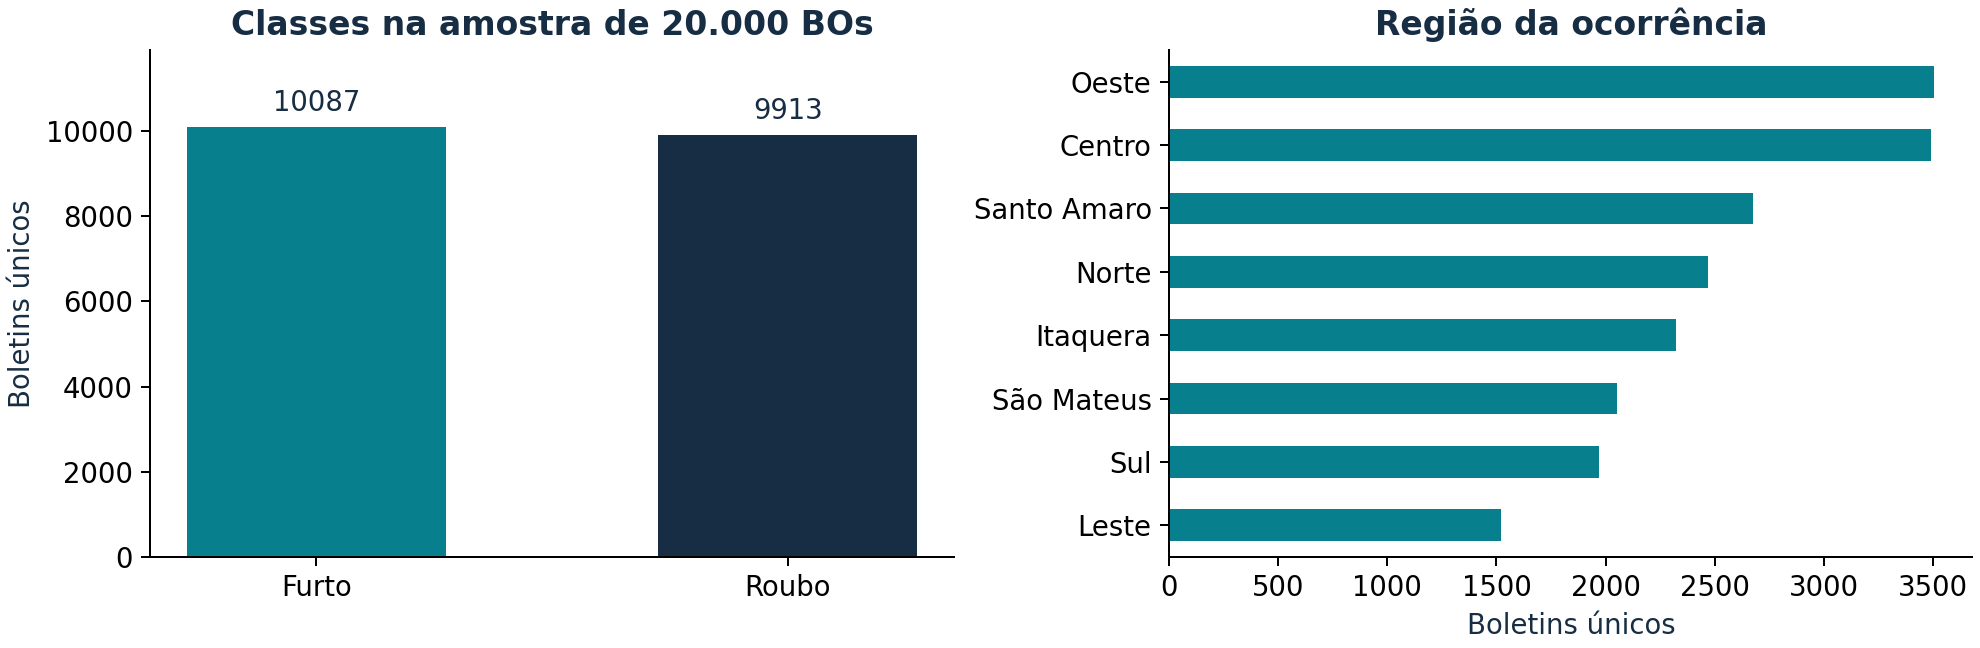

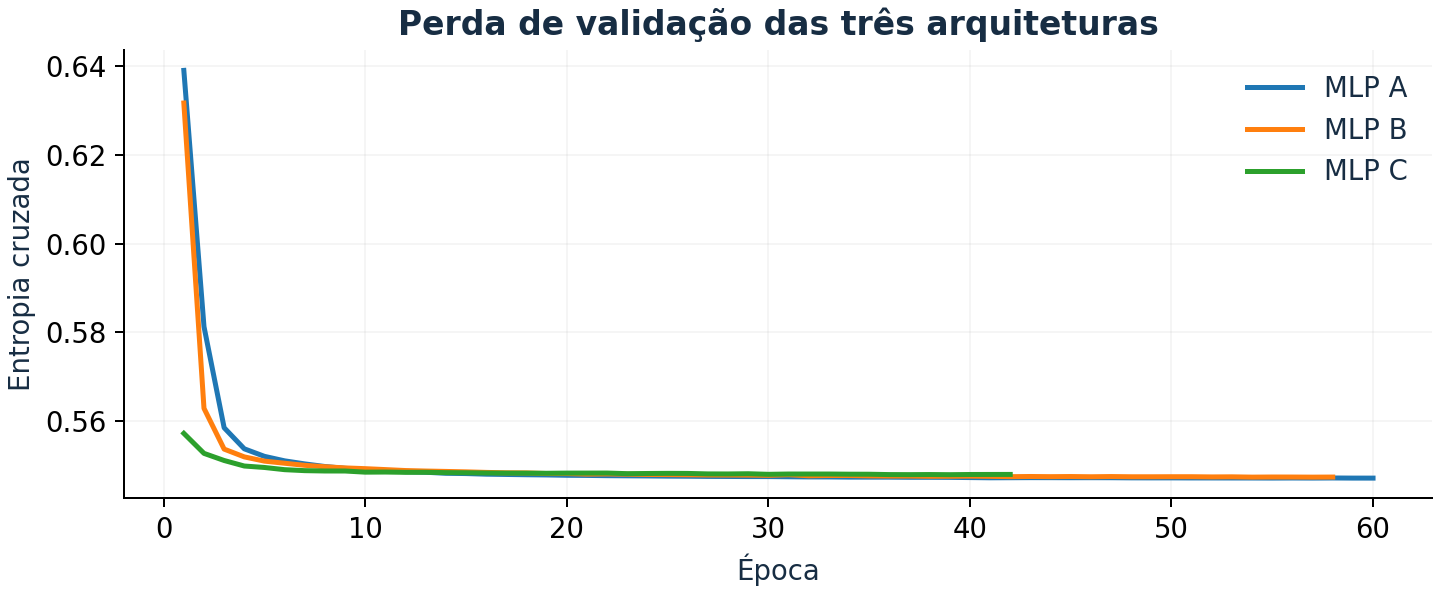

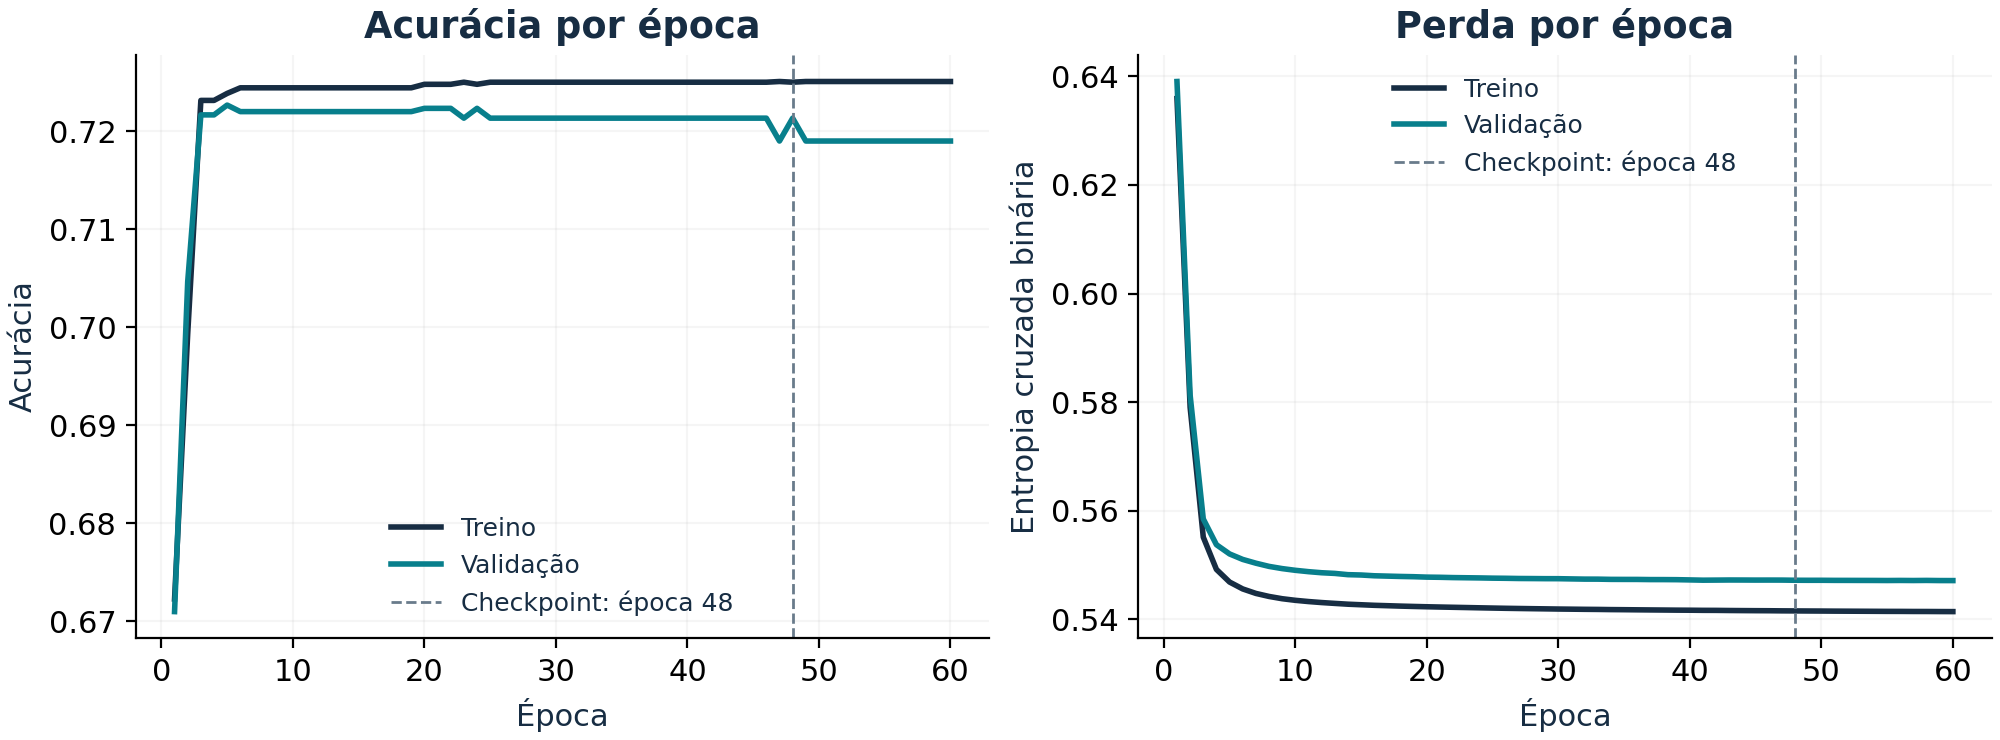

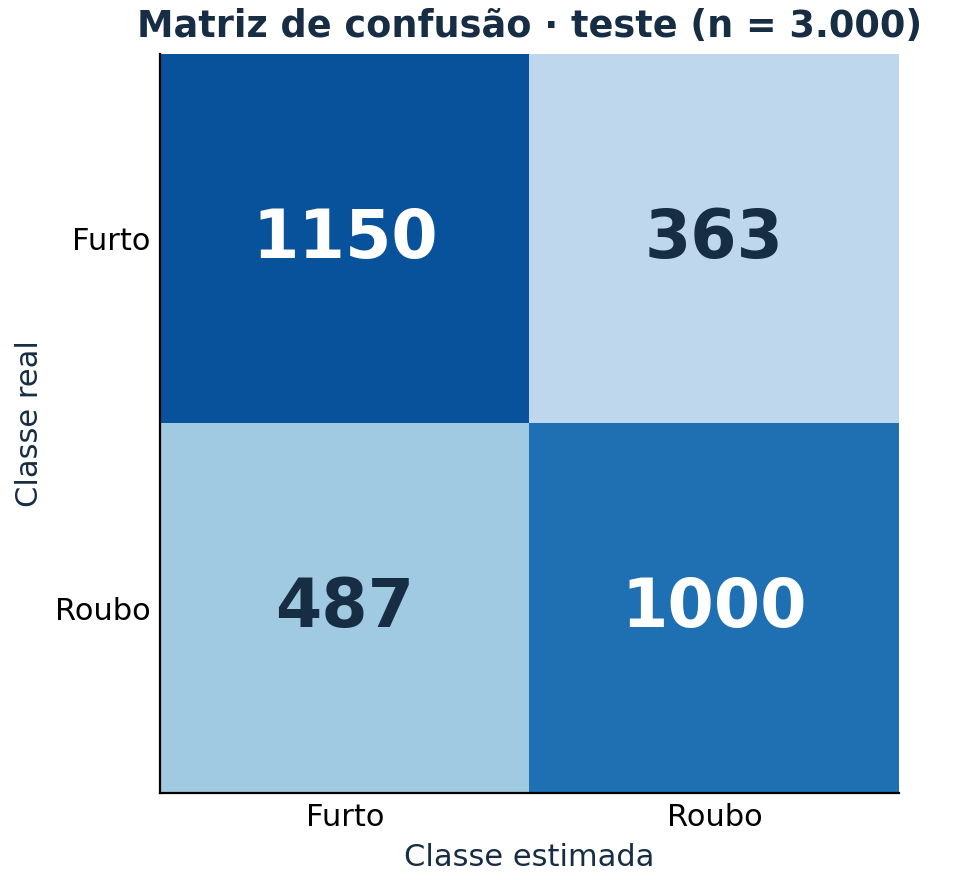

**Análise:** MLP A apresenta acurácia de treino de 72.50% e validação de 72.13%, diferença de 0.37 pontos percentuais. Não há gap grande de generalização nessa divisão. O desempenho moderado pode refletir o limite de informação das duas entradas. As diferenças de F1 entre as três redes são pequenas e não demonstram superioridade estatística. No teste final, a acurácia é 71.67% e o F1 macro é 0.7160.

In [14]:
from src.plots import make_figures
make_figures(frame, report, histories, ROOT / 'reports/figures')
display(Image(filename=str(ROOT / 'reports/figures/exploracao.png')))
display(Image(filename=str(ROOT / 'reports/figures/comparacao_curvas.png')))
display(Image(filename=str(ROOT / 'reports/figures/curvas_modelo_selecionado.png')))
display(Image(filename=str(ROOT / 'reports/figures/matriz_confusao.png')))
selected = next(r for r in report['configs'] if r['name']==report['selected'])
gap = selected['training']['accuracy'] - selected['validation']['accuracy']
display(Markdown(f"**Análise:** {report['selected']} apresenta acurácia de treino de {selected['training']['accuracy']:.2%} e validação de {selected['validation']['accuracy']:.2%}, diferença de {gap*100:.2f} pontos percentuais. Não há gap grande de generalização nessa divisão. O desempenho moderado pode refletir o limite de informação das duas entradas. As diferenças de F1 entre as três redes são pequenas e não demonstram superioridade estatística. No teste final, a acurácia é {report['test']['accuracy']:.2%} e o F1 macro é {report['test']['f1_macro']:.4f}."))

## 9. Exportação e integração web

Salvamos o modelo Python junto do encoder em `models/mlp_bundle.joblib` e exportamos as mesmas matrizes e vieses para `web/model.json`. A função JavaScript em `web/inference.js` executa one-hot, multiplicações de matrizes, ReLU e sigmoid. Nenhum número de saída é escolhido manualmente.

A aplicação não recebe dados pessoais, não exige API paga e executa a classificação no navegador. O teste de integração compara Python e JavaScript em **todas as 80 combinações conhecidas**, além de uma entrada desconhecida. A tolerância numérica é de $10^{-12}$.

In [15]:
def export_model(bundle, report, destination):
    """Exporta os pesos REAIS e o mesmo encoder. Saída JS igual à Python."""
    model, encoder = bundle["model"], bundle["encoder"]
    payload = {"format": "sklearn-mlp-binary-v1", "selected": bundle["selected"],
               "features": FEATURES, "categories": [a.tolist() for a in encoder.categories_],
               "weights": [w.tolist() for w in model.coefs_],
               "biases": [b.tolist() for b in model.intercepts_],
               "activation": "relu", "output_activation": "sigmoid",
               "classes": ["Furto", "Roubo"], "threshold": 0.5,
               "metrics": report["test"], "input_dimension": report["input_dimension"],
               "sample_size": sum(s["rows"] for s in report["splits"].values()),
               "year": 2016}
    Path(destination).write_text(json.dumps(payload, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")

In [16]:
def save_outputs(bundle, report, histories, membership, predictions, output_root=ROOT):
    output_root = Path(output_root)
    for directory in ["models", "reports", "web"]:
        (output_root / directory).mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, output_root / "models/mlp_bundle.joblib")
    (output_root / "reports/metrics.json").write_text(json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
    (output_root / "reports/histories.json").write_text(json.dumps(histories, indent=2), encoding="utf-8")
    membership.to_csv(output_root / "reports/split_membership.csv", index=False)
    predictions.to_csv(output_root / "reports/test_predictions.csv", index=False)
    rows = [{"architecture": r["name"], "layers": str(r["hidden_layers"]), **r["validation"]} for r in report["configs"]]
    pd.DataFrame(rows).to_csv(output_root / "reports/comparison_validation.csv", index=False)
    export_model(bundle, report, output_root / "web/model.json")

In [17]:
save_outputs(bundle, report, histories, membership, predictions)
from scripts.build_web import build_web
build_web()
example = pd.DataFrame([{'regiao':'Norte','contexto':'Transeunte'}])
proba = bundle['model'].predict_proba(bundle['encoder'].transform(example[FEATURES]))[0]
print('Exemplo hipotético:', example.to_dict('records')[0])
print(f'Probabilidades da classe: Furto={proba[0]:.4%}, Roubo={proba[1]:.4%}')
print('Interpretação: dado que uma ocorrência aconteceu, estas são as probabilidades das classes.')

Exemplo hipotético: {'regiao': 'Norte', 'contexto': 'Transeunte'}
Probabilidades da classe: Furto=22.5862%, Roubo=77.4138%
Interpretação: dado que uma ocorrência aconteceu, estas são as probabilidades das classes.


In [18]:
import subprocess
verification = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-v'],
                              cwd=ROOT, text=True, capture_output=True)
print(verification.stdout + verification.stderr)
assert verification.returncode == 0

test_export_matches_python_in_all_supported_combinations (test_pipeline.PipelineTest.test_export_matches_python_in_all_supported_combinations) ... ok
test_no_target_or_identifier_among_inputs (test_pipeline.PipelineTest.test_no_target_or_identifier_among_inputs) ... ok
test_saved_test_metrics_match_predictions (test_pipeline.PipelineTest.test_saved_test_metrics_match_predictions) ... ok
test_splits_are_disjoint_and_reproducible (test_pipeline.PipelineTest.test_splits_are_disjoint_and_reproducible) ... ok

----------------------------------------------------------------------
Ran 4 tests in 0.181s

OK



## 10. Conclusões, limitações e uso de IA generativa

A MLP aprende associações nos dados tabulares e supera a referência de classe majoritária neste recorte. A arquitetura mais profunda não apresentou ganho relevante. A rede menor tem 321 parâmetros e permite uma aplicação leve. A escolha decorre da validação, sem busca de hiperparâmetros no teste.

**Limitações:** base de 2016, cobertura e preenchimento heterogêneos, subnotificação, rótulos administrativos, duas entradas agregadas, possíveis diferenças de preenchimento de `CONDUTA` por natureza, ausência de calibração de probabilidades e uma única semente/divisão. Não usamos variáveis de violência ou ameaça, então o modelo não faz enquadramento jurídico. Os totais de BOs não equivalem à estatística criminal oficial, como informa a metodologia RDO.

**Próximos experimentos:** usar base mais recente com tipo de local independente da natureza, fazer ablação sem `CONDUTA`, repetir sementes e validar estabilidade temporal. Essas extensões exigem novo protocolo com teste futuro reservado, sem reutilizar este teste para decidir alterações.

**IA generativa:** ChatGPT/Codex auxiliou na escrita do código, preparação da interface, documentação e relatório. Os registros e os resultados exibidos são provenientes do processamento e treinamento executados. A equipe deve revisar o notebook e explicar as decisões, a chave de deduplicação, a codificação, a função de perda e os limites de interpretação. O guia `docs/GUIA_APRESENTACAO.md` apoia essa revisão.

**Execução web:** `python -m http.server 8000 --directory web`, depois abra `http://localhost:8000`. O endereço publicado está no README. `docs/CHECKLIST_ENTREGA.md` relaciona os materiais e o estado de publicação.